# TA-05: Klasifikasi Risiko Diabetes dengan Decision Tree

Notebook analisis untuk Tugas Akhir 05 (Pembelajaran Mesin). Alurnya mengikuti langkah-langkah tugas:
lanjutan TP-05, EDA dan pra-pemrosesan, dua model (A tanpa batasan dan B yang dipangkas), evaluasi dan perbandingan,
visualisasi serta interpretasi Model B, lalu penyimpanan model dengan Joblib untuk aplikasi Flask.

**Dataset:** Pima Indians Diabetes ([Kaggle](https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv)), 768 pasien wanita, target `Outcome` (1 = diabetes).

## 1. Lanjutan TP-05: memuat dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

File CSV ini **tidak punya baris header**, jadi nama kolom diberikan manual lewat `header=None, names=...`.

--- 5 Baris Pertama Data ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1

Ukuran data: (768, 9)

--- Jumlah per kelas ---
Outcome
0    500
1    268
Name: count, dtype: int64


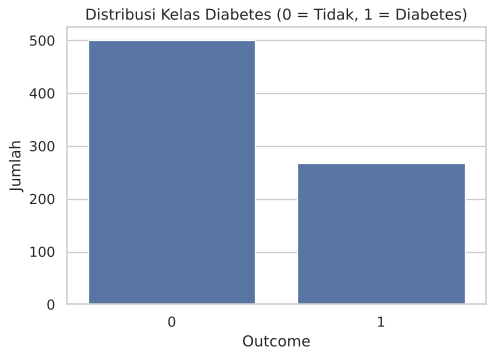

In [2]:
kolom = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
         "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
df = pd.read_csv("data/pima-indians-diabetes.csv", header=None, names=kolom)

print("--- 5 Baris Pertama Data ---")
print(df.head())
print("\nUkuran data:", df.shape)
print("\n--- Jumlah per kelas ---")
print(df["Outcome"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x="Outcome", data=df)
plt.title("Distribusi Kelas Diabetes (0 = Tidak, 1 = Diabetes)")
plt.xlabel("Outcome")
plt.ylabel("Jumlah")
plt.show()

Kelas tidak sepenuhnya seimbang: pasien non-diabetes sekitar dua kali lipat pasien diabetes (500 banding 268).

## 2. Eksplorasi data (EDA)

In [3]:
print(df.describe().T.round(2))
print("\nTipe data:")
print(df.dtypes)

                          count    mean     std    min    25%     50%     75%     max
Pregnancies               768.0    3.85    3.37   0.00   1.00    3.00    6.00   17.00
Glucose                   768.0  120.89   31.97   0.00  99.00  117.00  140.25  199.00
BloodPressure             768.0   69.11   19.36   0.00  62.00   72.00   80.00  122.00
SkinThickness             768.0   20.54   15.95   0.00   0.00   23.00   32.00   99.00
Insulin                   768.0   79.80  115.24   0.00   0.00   30.50  127.25  846.00
BMI                       768.0   31.99    7.88   0.00  27.30   32.00   36.60   67.10
DiabetesPedigreeFunction  768.0    0.47    0.33   0.08   0.24    0.37    0.63    2.42
Age                       768.0   33.24   11.76  21.00  24.00   29.00   41.00   81.00
Outcome                   768.0    0.35    0.48   0.00   0.00    0.00    1.00    1.00

Tipe data:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness       

Sebaran tiap fitur menurut kelas. Glukosa dan BMI paling jelas memisahkan kedua kelas.

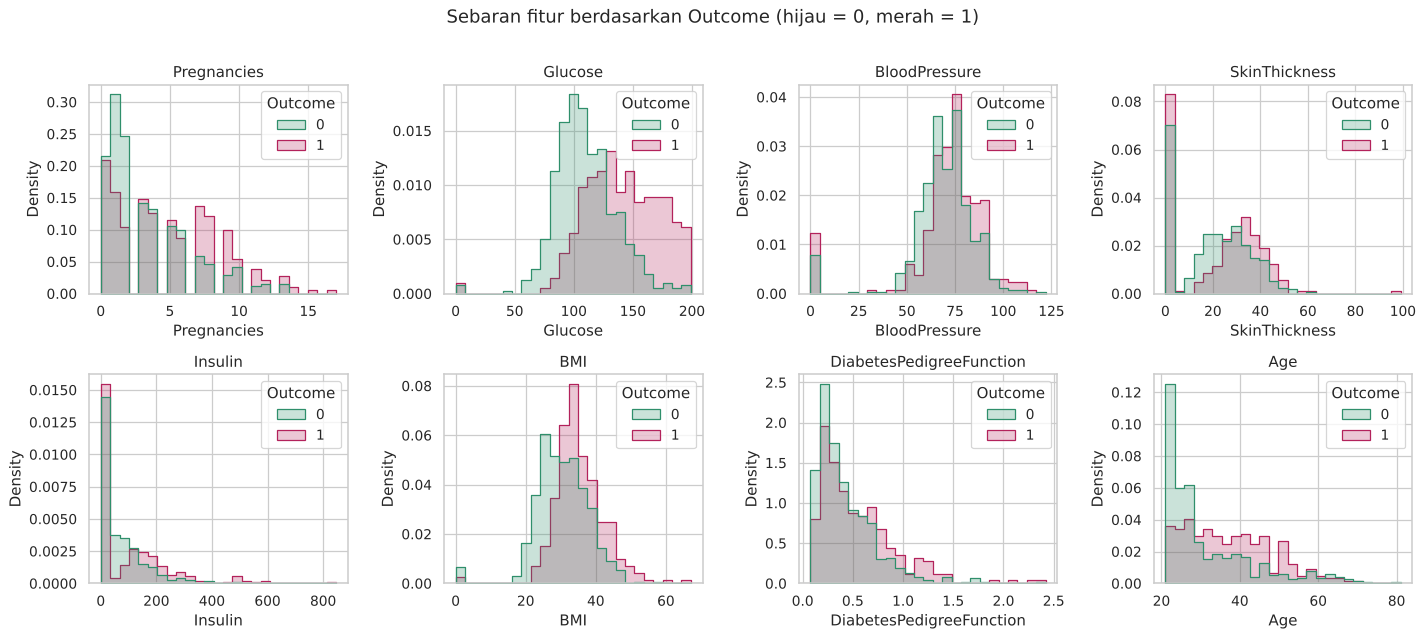

In [4]:
fitur = kolom[:-1]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), fitur):
    sns.histplot(data=df, x=f, hue="Outcome", bins=25, element="step", stat="density",
                 common_norm=False, ax=ax, palette={0: "#2F8F6B", 1: "#B3225B"})
    ax.set_title(f)
plt.suptitle("Sebaran fitur berdasarkan Outcome (hijau = 0, merah = 1)", y=1.01)
plt.tight_layout()
plt.show()

Korelasi tiap fitur dengan Outcome:
Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


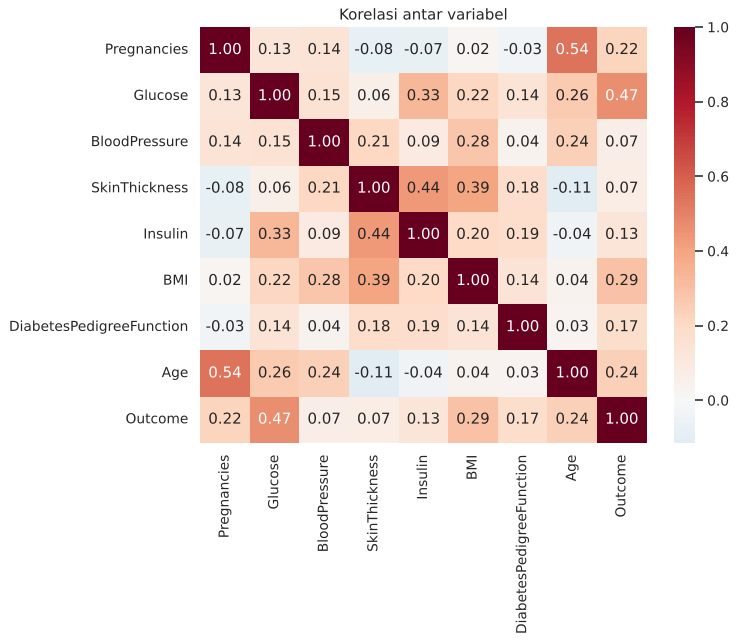

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Korelasi antar variabel")
plt.show()

print("Korelasi tiap fitur dengan Outcome:")
print(df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

## 3. Pra-pemrosesan

### 3a. Nilai yang hilang
Tidak ada sel kosong (`NaN`), tetapi lima kolom berisi angka **0 yang mustahil secara medis** (tekanan darah 0, BMI 0, dan sebagainya).
Angka 0 itu sebenarnya data hilang, jadi diubah menjadi `NaN` lalu diisi dengan **median**.

In [6]:
print("Jumlah NaN sebelum dibersihkan:", int(df.isna().sum().sum()))

kolom_nol = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nJumlah nilai 0 per kolom (dianggap data hilang):")
print((df[kolom_nol] == 0).sum())

df_bersih = df.copy()
df_bersih[kolom_nol] = df_bersih[kolom_nol].replace(0, np.nan)
print("\nJumlah NaN setelah angka 0 diganti NaN:")
print(df_bersih.isna().sum()[df_bersih.isna().sum() > 0])

Jumlah NaN sebelum dibersihkan: 0

Jumlah nilai 0 per kolom (dianggap data hilang):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Jumlah NaN setelah angka 0 diganti NaN:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


Median dihitung **hanya dari data latih** supaya tidak ada kebocoran informasi dari data uji. Karena itu pengisian dilakukan oleh
`SimpleImputer(strategy="median")` di dalam `Pipeline`, setelah data dibagi.

### 3b. Fitur kategorikal
Seluruh fitur dalam dataset ini sudah berupa angka (lihat tipe data di atas), jadi **tidak ada fitur kategorikal** yang perlu di-encode dengan One-Hot atau Label Encoding.

### 3c. Pembagian data
Data dibagi 80:20 dengan `stratify=y` agar proporsi kelas sama di data latih dan data uji.

In [7]:
X = df_bersih.drop(columns="Outcome")
y = df_bersih["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Data latih:", X_train.shape, " Data uji:", X_test.shape)
print("Proporsi diabetes - latih: %.3f, uji: %.3f" % (y_train.mean(), y_test.mean()))

Data latih: (614, 8)  Data uji: (154, 8)
Proporsi diabetes - latih: 0.349, uji: 0.351


## 4. Pengembangan model

- **Model A (potensi overfit):** `max_depth=None`, pohon tumbuh sampai semua daun murni.
- **Model B (di-pruning):** `max_depth=3`.

Kedua model memakai `class_weight="balanced"` agar kelas diabetes yang lebih sedikit tidak diabaikan. Ini penting karena pada skrining, melewatkan pasien diabetes lebih merugikan daripada salah menandai pasien sehat. Satu-satunya perbedaan A dan B adalah `max_depth`, jadi perbandingannya adil.

In [8]:
def buat_model(max_depth):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeClassifier(max_depth=max_depth, class_weight="balanced",
                                        random_state=RANDOM_STATE)),
    ])

model_a = buat_model(None).fit(X_train, y_train)
model_b = buat_model(3).fit(X_train, y_train)

for nama, m in [("Model A", model_a), ("Model B", model_b)]:
    t = m.named_steps["tree"]
    print(f"{nama}: kedalaman = {t.get_depth()}, jumlah daun = {t.get_n_leaves()}")

Model A: kedalaman = 15, jumlah daun = 119
Model B: kedalaman = 3, jumlah daun = 8


## 5. Evaluasi dan perbandingan model

In [9]:
nama_kelas = ["Tidak diabetes", "Diabetes"]
hasil = {}
for nama, m in [("Model A", model_a), ("Model B", model_b)]:
    pred = m.predict(X_test)
    hasil[nama] = {"model": m, "pred": pred}
    print("=" * 60)
    print(nama)
    print("=" * 60)
    print("--- Confusion Matrix ---")
    print(confusion_matrix(y_test, pred))
    print("\n--- Classification Report ---")
    print(classification_report(y_test, pred, target_names=nama_kelas))

Model A
--- Confusion Matrix ---
[[84 16]
 [28 26]]

--- Classification Report ---
                precision    recall  f1-score   support

Tidak diabetes       0.75      0.84      0.79       100
      Diabetes       0.62      0.48      0.54        54

      accuracy                           0.71       154
     macro avg       0.68      0.66      0.67       154
  weighted avg       0.70      0.71      0.70       154

Model B
--- Confusion Matrix ---
[[59 41]
 [ 9 45]]

--- Classification Report ---
                precision    recall  f1-score   support

Tidak diabetes       0.87      0.59      0.70       100
      Diabetes       0.52      0.83      0.64        54

      accuracy                           0.68       154
     macro avg       0.70      0.71      0.67       154
  weighted avg       0.75      0.68      0.68       154


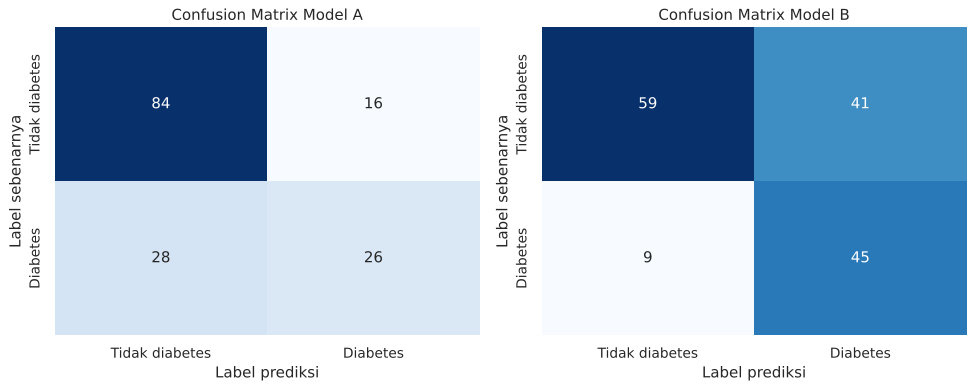

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nama, h) in zip(axes, hasil.items()):
    cm = confusion_matrix(y_test, h["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=nama_kelas, yticklabels=nama_kelas)
    ax.set_title(f"Confusion Matrix {nama}")
    ax.set_xlabel("Label prediksi")
    ax.set_ylabel("Label sebenarnya")
plt.tight_layout()
plt.show()

### Perbandingan overfitting: data latih vs data uji vs validasi silang

In [11]:
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
baris = []
for nama, h in hasil.items():
    m = h["model"]
    cv = cross_validate(m, X_train, y_train, cv=skf, scoring=["accuracy", "recall", "roc_auc"])
    baris.append({
        "Model": nama,
        "Akurasi latih": m.score(X_train, y_train),
        "Akurasi uji": m.score(X_test, y_test),
        "Selisih (poin)": 100 * (m.score(X_train, y_train) - m.score(X_test, y_test)),
        "Akurasi CV": cv["test_accuracy"].mean(),
        "Recall CV": cv["test_recall"].mean(),
        "AUC uji": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
        "AUC CV": cv["test_roc_auc"].mean(),
    })
perbandingan = pd.DataFrame(baris).set_index("Model").round(3)
print(perbandingan.T)

Model           Model A  Model B
Akurasi latih     1.000    0.731
Akurasi uji       0.714    0.675
Selisih (poin)   28.571    5.595
Akurasi CV        0.673    0.697
Recall CV         0.533    0.837
AUC uji           0.661    0.762
AUC CV            0.640    0.796


max_depth  latih   uji  CV akurasi  CV AUC
        1  0.744 0.701       0.736   0.710
        2  0.744 0.701       0.736   0.767
        3  0.731 0.675       0.697   0.796
        4  0.772 0.708       0.707   0.786
        5  0.839 0.727       0.718   0.771
        6  0.852 0.701       0.700   0.753
        8  0.909 0.682       0.678   0.698
       10  0.963 0.708       0.679   0.680
     None  1.000 0.714       0.673   0.640


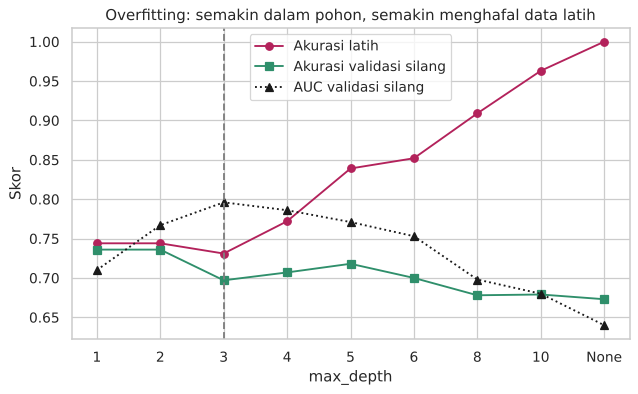

In [12]:
# Efek max_depth: akurasi latih terus naik, tetapi validasi silang tidak ikut naik
kedalaman = [1, 2, 3, 4, 5, 6, 8, 10, None]
sapuan = []
for d in kedalaman:
    m = buat_model(d).fit(X_train, y_train)
    cv = cross_validate(buat_model(d), X_train, y_train, cv=skf, scoring=["accuracy", "roc_auc"])
    sapuan.append({"max_depth": "None" if d is None else d,
                   "latih": m.score(X_train, y_train),
                   "uji": m.score(X_test, y_test),
                   "CV akurasi": cv["test_accuracy"].mean(),
                   "CV AUC": cv["test_roc_auc"].mean()})
sapuan = pd.DataFrame(sapuan).round(3)
print(sapuan.to_string(index=False))

plt.figure(figsize=(8, 4.5))
x = sapuan["max_depth"].astype(str)
plt.plot(x, sapuan["latih"], marker="o", color="#B3225B", label="Akurasi latih")
plt.plot(x, sapuan["CV akurasi"], marker="s", color="#2F8F6B", label="Akurasi validasi silang")
plt.plot(x, sapuan["CV AUC"], marker="^", color="k", ls=":", label="AUC validasi silang")
plt.axvline("3", color="gray", ls="--")
plt.xlabel("max_depth")
plt.ylabel("Skor")
plt.title("Overfitting: semakin dalam pohon, semakin menghafal data latih")
plt.legend()
plt.show()

### Analisis perbandingan

- **Model A menghafal data latih.** Akurasi latihnya 100% dengan 119 daun, tetapi turun menjadi sekitar 71% pada data uji, selisih sekitar 29 poin. Itu tanda khas overfitting. Model B selisihnya hanya sekitar 6 poin.
- **Akurasi uji Model A sedikit lebih tinggi daripada Model B** (sekitar 71% dibanding 68%), jadi dugaan bahwa "Model A selalu lebih rendah di data uji" **tidak terbukti pada pembagian data ini**. Selisih sebesar itu hanya sekitar 6 pasien dari 154 pasien uji, jadi wajar bila masih dalam batas kebetulan.
- **Ukuran yang lebih bermakna menunjukkan Model B lebih baik.** AUC data uji Model B sekitar 0,76 (Model A 0,66), AUC validasi silang sekitar 0,80 (Model A 0,64), dan recall diabetes sekitar 83% (Model A 48%). Akurasi validasi silang Model B (sekitar 70%) juga lebih tinggi daripada Model A (sekitar 67%).
- **Harga yang dibayar Model B:** precision diabetes lebih rendah (sekitar 52% dibanding 62%), artinya lebih banyak pasien sehat yang ikut ditandai berisiko (41 dibanding 16 pasien). Untuk skrining, ini pertukaran yang masuk akal karena Model B hanya melewatkan 9 pasien diabetes, sedangkan Model A melewatkan 28.
- **Memilih `max_depth=3`.** Kedalaman 3 memberi AUC validasi silang tertinggi, dan pohonnya hanya 8 daun sehingga mudah dibaca.

## 6. Visualisasi dan interpretasi Model B

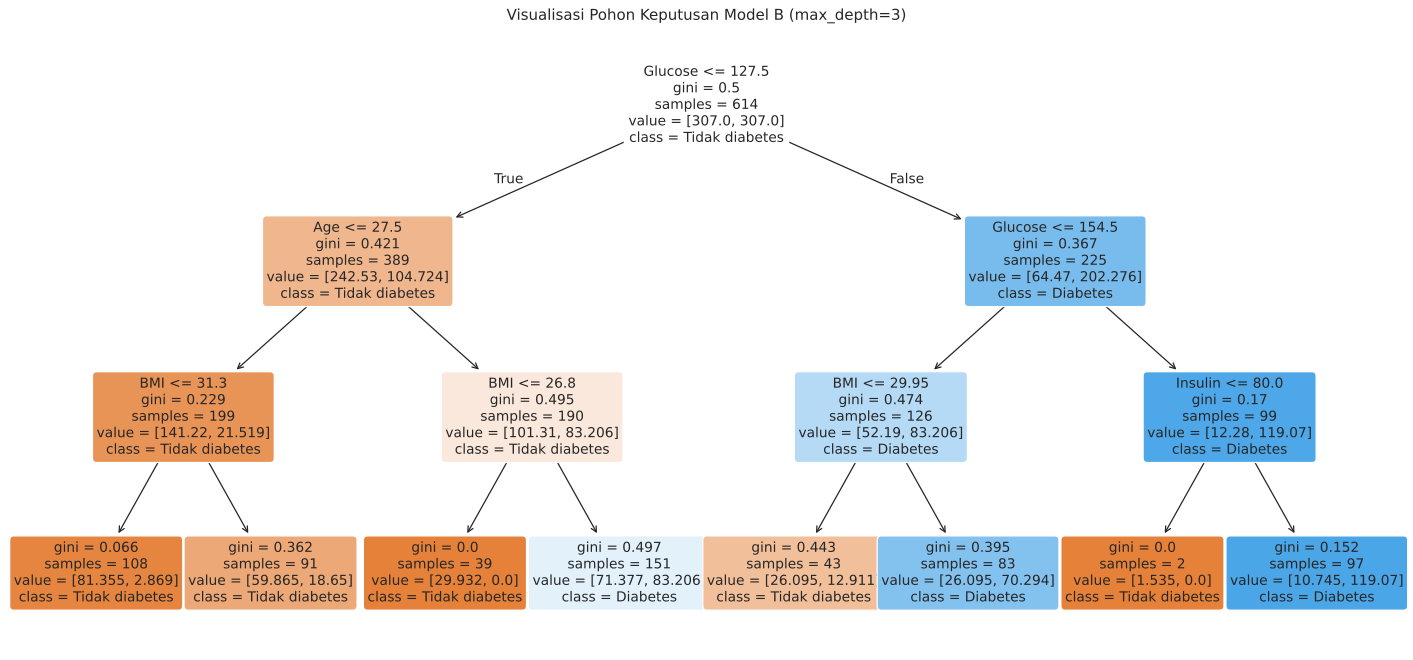

In [13]:
tree_b = model_b.named_steps["tree"]
nama_fitur = list(X.columns)

plt.figure(figsize=(20, 9))
plot_tree(tree_b, feature_names=nama_fitur, class_names=nama_kelas,
          filled=True, rounded=True, fontsize=11)
plt.title("Visualisasi Pohon Keputusan Model B (max_depth=3)")
plt.show()

Catatan membaca gambar: karena memakai `class_weight="balanced"`, angka `value` pada kotak adalah **jumlah berbobot**, bukan jumlah pasien asli. Jumlah pasien asli per kotak ada di bagian `samples` dan di tabel aturan di bawah.

In [14]:
print(export_text(tree_b, feature_names=nama_fitur))

|--- Glucose <= 127.50
|   |--- Age <= 27.50
|   |   |--- BMI <= 31.30
|   |   |   |--- class: 0
|   |   |--- BMI >  31.30
|   |   |   |--- class: 0
|   |--- Age >  27.50
|   |   |--- BMI <= 26.80
|   |   |   |--- class: 0
|   |   |--- BMI >  26.80
|   |   |   |--- class: 1
|--- Glucose >  127.50
|   |--- Glucose <= 154.50
|   |   |--- BMI <= 29.95
|   |   |   |--- class: 0
|   |   |--- BMI >  29.95
|   |   |   |--- class: 1
|   |--- Glucose >  154.50
|   |   |--- Insulin <= 80.00
|   |   |   |--- class: 0
|   |   |--- Insulin >  80.00
|   |   |   |--- class: 1


In [15]:
# Jumlah pasien latih ASLI di setiap daun
Xi = model_b.named_steps["imputer"].transform(X_train)
daun = tree_b.apply(Xi)
tabel = (pd.DataFrame({"daun": daun, "diabetes": y_train.values})
         .groupby("daun").agg(pasien=("diabetes", "size"), diabetes=("diabetes", "sum")))
tabel["persen_diabetes"] = (100 * tabel["diabetes"] / tabel["pasien"]).round(1)
tabel["prediksi"] = [nama_kelas[int(tree_b.tree_.value[i][0].argmax())] for i in tabel.index]
print(tabel)

      pasien  diabetes  persen_diabetes        prediksi
daun                                                   
3        108         2              1.9  Tidak diabetes
4         91        13             14.3  Tidak diabetes
6         39         0              0.0  Tidak diabetes
7        151        58             38.4        Diabetes
10        43         9             20.9  Tidak diabetes
11        83        49             59.0        Diabetes
13         2         0              0.0  Tidak diabetes
14        97        83             85.6        Diabetes


### Tiga jalur dari akar ke daun sebagai aturan jika-maka

1. **Jika** glukosa ≤ 127,5 **dan** usia ≤ 27,5 **dan** BMI ≤ 31,3, **maka** prediksinya **Tidak diabetes**. Hanya 2 dari 108 pasien latih di jalur ini yang diabetes (sekitar 2%).
2. **Jika** glukosa > 127,5 **dan** glukosa > 154,5 **dan** insulin > 80, **maka** prediksinya **Diabetes**. Sebanyak 83 dari 97 pasien latih di jalur ini diabetes (sekitar 86%), jalur dengan keyakinan paling tinggi.
3. **Jika** glukosa ≤ 127,5 **dan** usia > 27,5 **dan** BMI > 26,8, **maka** prediksinya **Diabetes**. Di jalur ini 58 dari 151 pasien latih diabetes (sekitar 38%). Prediksinya tetap "Diabetes" karena `class_weight="balanced"` menurunkan ambang risiko menjadi sekitar 35%, bukan 50%.

Pola yang terbaca masuk akal secara medis: glukosa tinggi adalah penentu utama, lalu BMI dan usia memperkuat risiko.

                   Fitur  Pentingnya
                 Glucose       0.613
                     BMI       0.220
                     Age       0.145
                 Insulin       0.021
           SkinThickness       0.000
           BloodPressure       0.000
             Pregnancies       0.000
DiabetesPedigreeFunction       0.000


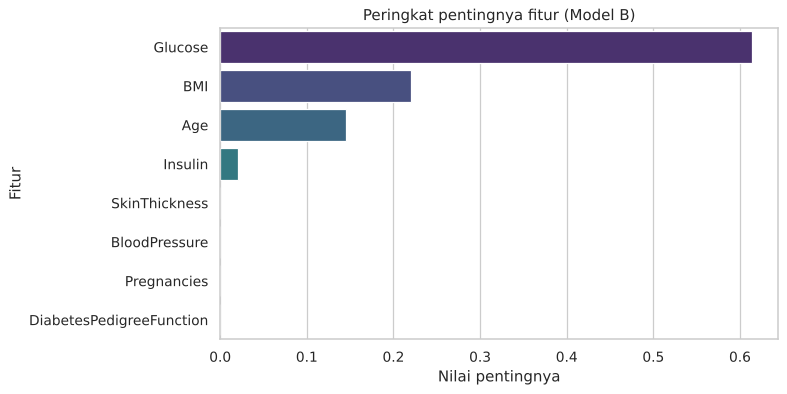

In [16]:
imp = (pd.DataFrame({"Fitur": nama_fitur, "Pentingnya": tree_b.feature_importances_})
       .sort_values("Pentingnya", ascending=False))
print(imp.round(3).to_string(index=False))

plt.figure(figsize=(8, 4.5))
sns.barplot(x="Pentingnya", y="Fitur", data=imp, palette="viridis")
plt.title("Peringkat pentingnya fitur (Model B)")
plt.xlabel("Nilai pentingnya")
plt.show()

**Feature importance:** Glukosa mendominasi (sekitar 61%), diikuti BMI (22%) dan usia (15%). Insulin hanya sekitar 2%, sedangkan jumlah kehamilan, tekanan darah, tebal lipatan kulit, dan riwayat keluarga **tidak dipakai sama sekali** oleh pohon sedalam tiga tingkat ini. Itu tidak berarti fitur tersebut tidak berguna secara medis, hanya bahwa pohon kecil ini tidak membutuhkannya.

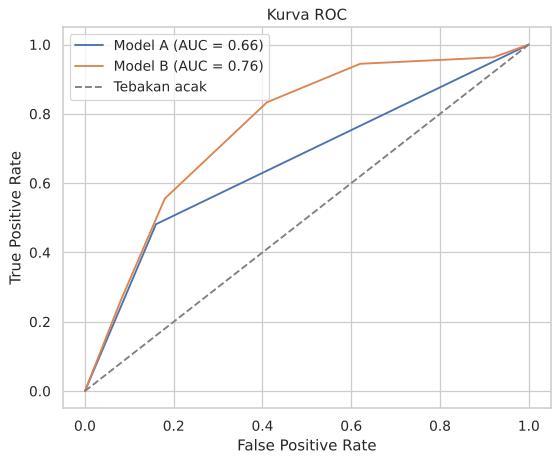

In [17]:
plt.figure(figsize=(7, 5.5))
for nama, h in hasil.items():
    proba = h["model"].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nama} (AUC = {roc_auc_score(y_test, proba):.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Kurva ROC")
plt.legend()
plt.show()

## 7. Menyimpan model dengan Joblib

Yang disimpan adalah seluruh `Pipeline` Model B (pengisi median + pohon), sehingga aplikasi Flask cukup memanggil `predict` pada input mentah.

In [18]:
import os
os.makedirs("model", exist_ok=True)
joblib.dump(model_b, "model/model.joblib")

muat_ulang = joblib.load("model/model.joblib")
contoh = pd.DataFrame([[6, 148, 72, 35, np.nan, 33.6, 0.627, 50]], columns=nama_fitur)
print("Prediksi contoh (baris pertama dataset, insulin kosong):", nama_kelas[int(muat_ulang.predict(contoh)[0])])

Prediksi contoh (baris pertama dataset, insulin kosong): Diabetes


## 8. Kesimpulan

1. Decision Tree dapat memprediksi diabetes dengan AUC sekitar 0,76 pada data uji. Hasil ini cukup untuk alat bantu belajar, tetapi **bukan alat diagnosis**.
2. Model tanpa batasan (A) jelas overfit: akurasi latih 100% dengan 119 daun. Pemangkasan `max_depth=3` (B) membuat pohon sederhana (8 daun), lebih stabil pada validasi silang, dan jauh lebih peka terhadap pasien diabetes (recall sekitar 83% dibanding 48%).
3. Akurasi pada satu pembagian data bisa menyesatkan. Pada data uji, Model A bahkan sedikit lebih akurat, namun AUC, recall, dan validasi silang menunjukkan Model B lebih layak dipakai.
4. Keunggulan Decision Tree adalah transparansinya: setiap prediksi dapat dijelaskan lewat jalur jika-maka. Aplikasi Flask menampilkan jalur ini untuk setiap pasien.
5. Keterbatasan: data hanya mencakup wanita suku Pima berusia 21 tahun ke atas, sebagian kolom punya banyak data hilang (insulin sekitar 49%), dan datanya hanya 768 baris.